# Notebook 13E — Final retraining findings and conclusions

**Research question:** Did adding more recent, mature Freddie Mac loans improve mortgage credit-risk model reliability?

We summarize the **frozen Logistic Regression benchmark**, the **frozen XGBoost primary model**, and the two **updated XGBoost** models (Policy A and Policy B). We do not refit, recalibrate, or tune any model here.

**Sources:** Notebook 11 frozen-model out-of-time evaluation, Notebook 13/Stage 2 training manifest, Notebook 13B paired evaluation, Notebook 13C diagnostics and Notebook 13D Policy A sensitivity.

**Scope:** A retrospective exploratory experiment. The January 2023 data-availability assumptions use proxies, and the 2023 outcomes had been examined before these sensitivity comparisons. This is not independent prospective validation. Logistic Regression was **not** included in the retraining experiments.

## 1. Locate the saved evidence and verify provenance

Use the result files already written by earlier notebooks. Check the model, data and contract fingerprints and identify the saved Policy A run. Do not load or fit an estimator.

In [1]:
from pathlib import Path
import hashlib, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from IPython.display import display

ROOT = (Path.cwd().parent if Path.cwd().name.lower() == 'notebooks' else Path.cwd()).resolve()
DATA = ROOT / 'data' / 'processed' / 'Freddie_Mac'
BASE = DATA / 'model_baselines_2015_2017'
OOT = BASE / 'oot_evaluation'
RUN_ID_B = '20261111T161902005765Z'
B_DIR = DATA / 'notebook_13_updated_xgboost' / RUN_ID_B
DIR_13B = DATA / 'notebook_13_retraining_evaluation' / RUN_ID_B
DIR_13C = DATA / 'notebook_13_retraining_diagnostics' / RUN_ID_B
A_ROOT = DATA / 'notebook_13_policy_a_sensitivity'
OUTPUT_DIR = DATA / 'notebook_13_final_retraining_synthesis' / RUN_ID_B

BASE_MANIFEST = BASE / 'model_manifest.json'
FEATURE_CONTRACT = BASE / 'freddie_feature_contract.json'
B_MANIFEST = B_DIR / 'updated_model_manifest.json'
B_REVIEW = DIR_13B / 'evaluation_manifest.json'
C_REVIEW = DIR_13C / 'diagnostics_manifest.json'
OOT_SUMMARY = OOT / 'cohort_reliability_summary.csv'
OOT_PREDICTIONS = OOT / 'oot_predictions_2018_2023.parquet'

def require(ok, message):
    if not ok:
        raise ValueError(message)

def sha256(path):
    with Path(path).open('rb') as f:
        return hashlib.file_digest(f, 'sha256').hexdigest()

def read_json(path):
    require(path.is_file(), f'Missing saved file: {path}')
    return json.loads(path.read_text(encoding='utf-8'))

for path in [OOT_SUMMARY, OOT_PREDICTIONS, BASE_MANIFEST, FEATURE_CONTRACT,
             B_MANIFEST, B_REVIEW, C_REVIEW]:
    require(path.is_file(), f'Required prior result is missing: {path}')
base = read_json(BASE_MANIFEST)
b_info = read_json(B_MANIFEST)
b_review = read_json(B_REVIEW)
c_review = read_json(C_REVIEW)
require(base['development_years'] == [2015, 2016, 2017], 'Original development period differs.')
require(len(base['predictors']) == 29, 'The predictor contract differs.')
require(sha256(FEATURE_CONTRACT) == base['feature_contract_sha256']
        == b_info['original_feature_contract_sha256'], 'Feature contract fingerprint differs.')
require(b_info['decision_month'] == '2023-01'
        and b_info['primary_training_policy'] == 'B_full_window_individual'
        and b_info['sample_rows'] == 285070
        and b_info['sample_events'] == 5179,
        'Policy B configuration differs from the reviewed run.')
require(b_review['frozen_model_sha256'] == b_info['frozen_model_sha256']
        and b_review['updated_model_sha256'] == b_info['updated_model_sha256'],
        'Notebook 13B did not use the expected model artifacts.')
require(c_review['stage2_run_id'] == RUN_ID_B
        and c_review['frozen_model_sha256'] == b_review['frozen_model_sha256']
        and c_review['updated_model_sha256'] == b_review['updated_model_sha256'],
        'Notebook 13C model fingerprints differ.')
require(c_review['evaluation_loans'] == b_review['evaluation_loans'] == 49501
        and c_review['evaluation_events'] == b_review['evaluation_events'] == 876,
        'Notebook 13B/13C evaluation counts differ.')
require(c_review['modeling_data_sha256'] == b_review['model_data_sha256']
        and c_review['modeling_data_sha256'] == base['input_file_sha256'],
        'Modeling data fingerprints differ.')

# Select the Policy A saved run by its fingerprint and reviewed study design.
a_candidates = []
for path in sorted(A_ROOT.glob('*/policy_a_sensitivity_manifest.json')):
    info = read_json(path)
    if (info.get('policy_b_stage2_run_id') == RUN_ID_B
            and info.get('decision_month') == '2023-01'
            and info.get('frozen_model_sha256') == b_review['frozen_model_sha256']
            and info.get('policy_b_model_sha256') == b_review['updated_model_sha256']
            and info.get('training_loans') == 191015
            and info.get('training_events') == 2185
            and info.get('evaluation_loans') == 49501
            and info.get('evaluation_events') == 876):
        a_candidates.append((path.parent, info))
require(a_candidates, f'No matching completed Policy A run under: {A_ROOT}')
A_DIR, a_info = a_candidates[-1]
if len(a_candidates) > 1:
    print(f'Found {len(a_candidates)} matching Policy A runs; using newest folder: {A_DIR.name}')

frozen_path = BASE / base['models']['xgboost']['artifact']
logistic_path = BASE / base['models']['logistic']['artifact']
b_path = B_DIR / b_info['model_filename']
a_path = A_DIR / a_info['policy_a_model_filename']
for name, path, expected in [
    ('frozen XGBoost', frozen_path, base['models']['xgboost']['sha256']),
    ('frozen Logistic Regression', logistic_path, base['models']['logistic']['sha256']),
    ('Policy B XGBoost', b_path, b_info['updated_model_sha256']),
    ('Policy A XGBoost', a_path, a_info['policy_a_model_sha256']),
]:
    require(path.is_file() and sha256(path) == expected,
            f'{name} model file is missing or does not match its saved fingerprint: {path}')
require(a_info['predictor_count'] == 29
        and a_info['xgboost_settings_unchanged'] is True
        and a_info['original_fitted_preprocessing_reused'] is True,
        'Policy A did not preserve the original feature/model contract.')
print('Evidence verified. No model fitting or scoring is performed in this section.')
print('Policy A results:', A_DIR)
print('Policy B results:', DIR_13B)
print('Notebook 13C diagnostics:', DIR_13C)

Evidence verified. No model fitting or scoring is performed in this section.
Policy A results: E:\capstone_project\mortgage-model-reliability\data\processed\Freddie_Mac\notebook_13_policy_a_sensitivity\20261111T173300818646Z
Policy B results: E:\capstone_project\mortgage-model-reliability\data\processed\Freddie_Mac\notebook_13_retraining_evaluation\20261111T161902005765Z
Notebook 13C diagnostics: E:\capstone_project\mortgage-model-reliability\data\processed\Freddie_Mac\notebook_13_retraining_diagnostics\20261111T161902005765Z


## 2. Reconcile the XGBoost retraining comparison

Check that the Notebook 13D three-model tables reproduce Notebook 13B results and that the Notebook 13C metrics agree. We compare the same 2023-H1, 2023-H2 and combined 2023 evaluation populations.

The **positive improvement** convention is consistent across results: positive favors the first model in a pair, whether higher ROC-AUC/AP or lower Brier/absolute risk gap is better.

In [2]:
def read_table(folder, filename):
    path = folder / filename
    require(path.is_file(), f'Missing reviewed result: {path}')
    return pd.read_csv(path)

three = read_table(A_DIR, 'three_model_reliability_metrics.csv')
paired = read_table(A_DIR, 'three_model_paired_intervals.csv')
points = read_table(A_DIR, 'three_model_point_comparisons.csv')
cohort_a = read_table(A_DIR, 'policy_a_training_cohorts.csv')
eval_cohorts = read_table(A_DIR, 'evaluation_cohorts.csv')
ref_13b = read_table(DIR_13B, 'frozen_updated_metrics.csv')
ref_13c = read_table(DIR_13C, 'reference_metrics_check.csv')
common_deciles = read_table(A_DIR, 'common_frozen_score_deciles.csv')

required_metrics = {'period','model','loans','events','prevalence','roc_auc',
                    'average_precision','brier','risk_gap','absolute_risk_gap',
                    'mean_predicted_risk'}
require(required_metrics.issubset(three.columns), 'Three-model metric columns differ.')
require(len(three) == 9 and not three.duplicated(['period','model']).any(),
        'Expected 3 periods by 3 XGBoost models.')
require(set(three['period']) == {'2023-H1','2023-H2','2023-all'}
        and set(three['model']) == {'frozen','policy_a','policy_b'},
        'Unexpected evaluation periods or XGBoost models.')
require(int(cohort_a['loans'].sum()) == a_info['training_loans'] == 191015
        and int(cohort_a['events'].sum()) == a_info['training_events'] == 2185,
        'Policy A training population differs.')
require(int(eval_cohorts['loans'].sum()) == 49501
        and int(eval_cohorts['events'].sum()) == 876,
        '2023 cohort totals differ.')
for _, row in three.iterrows():
    expected_n, expected_events = ((24757, 460) if row['period'] == '2023-H1'
                                   else (24744, 416) if row['period'] == '2023-H2'
                                   else (49501, 876))
    require(int(row['loans']) == expected_n and int(row['events']) == expected_events,
            f"Evaluation counts differ: {row['period']} / {row['model']}")
    np.testing.assert_allclose(row['prevalence'], expected_events/expected_n, rtol=1e-10)
    np.testing.assert_allclose(row['risk_gap'], row['prevalence']-row['mean_predicted_risk'], atol=1e-12)
    np.testing.assert_allclose(row['absolute_risk_gap'], abs(row['risk_gap']), atol=1e-12)

numeric = ['loans','events','prevalence','roc_auc','average_precision','brier',
           'risk_gap','absolute_risk_gap','mean_predicted_risk']
now = three.loc[three.model.isin(['frozen','policy_b'])].copy()
now['model'] = now['model'].replace({'policy_b':'updated'})
now = now.sort_values(['period','model']).reset_index(drop=True)
for label, prior in [('13B',ref_13b),('13C',ref_13c)]:
    prior = prior.sort_values(['period','model']).reset_index(drop=True)
    require(now[['period','model']].equals(prior[['period','model']]),
            f'{label} model/period coverage differs.')
    for col in numeric:
        np.testing.assert_allclose(now[col], prior[col], rtol=1e-8, atol=1e-10,
                                   err_msg=f'{label} differs on {col}')

metrics = ['roc_auc','average_precision','brier','absolute_risk_gap']
pairs = [('policy_a','frozen'),('policy_b','frozen'),('policy_a','policy_b')]
require(len(points)==36 and len(paired)==36, 'Expected 36 paired point/interval rows.')
require(not paired.duplicated(['period','comparison','metric']).any(),
        'Duplicate paired comparison records.')
check = points.merge(paired, on=['period','comparison','metric'], suffixes=('_point','_paired'),
                     validate='one_to_one')
require(len(check)==36, 'Not all point comparisons have paired intervals.')
for col in ['first','second','improvement']:
    np.testing.assert_allclose(check[col+'_point'], check[col+'_paired'], atol=1e-12)
require(paired['valid_draws'].ge(900).all()
        and paired['ci_low'].le(paired['ci_high']).all(), 'Bootstrap intervals are invalid.')
for _, row in paired.iterrows():
    direction = ('favors_first' if row['ci_low'] > 0 else
                 'favors_second' if row['ci_high'] < 0 else 'uncertain')
    require(row['direction'] == direction, 'Recorded interval direction differs.')
    first, second = next(((a,b) for a,b in pairs if row['comparison']==f'{a}_minus_{b}'), (None,None))
    require(first is not None and row['metric'] in metrics, 'Unexpected pair or metric.')
    a = three.loc[(three.period==row['period']) & (three.model==first),row['metric']].iloc[0]
    b = three.loc[(three.period==row['period']) & (three.model==second),row['metric']].iloc[0]
    expected = a-b if row['metric'] in ['roc_auc','average_precision'] else b-a
    np.testing.assert_allclose(expected, row['improvement'], atol=1e-12)

combined = three.loc[three.period.eq('2023-all')].copy()
combined['model'] = combined['model'].replace({
    'frozen':'Frozen XGBoost', 'policy_a':'Policy A XGBoost', 'policy_b':'Policy B XGBoost'})
main_cols=['model','loans','events','roc_auc','average_precision','brier',
           'mean_predicted_risk','absolute_risk_gap']
display(combined[main_cols].round(6))
print('Notebook 13D, 13B and 13C metrics reconcile. Paired confidence intervals verified.')

,model,loans,events,roc_auc,average_precision,brier,mean_predicted_risk,absolute_risk_gap
6,Frozen XGBoost,49501,876,0.786574,0.059271,0.017097,0.012123,0.005573
7,Policy A XGBoost,49501,876,0.760962,0.053512,0.022670,0.079740,0.062044
8,Policy B XGBoost,49501,876,0.776548,0.056100,0.022073,0.072630,0.054934


Notebook 13D, 13B and 13C metrics reconcile. Paired confidence intervals verified.


## 3. Include the frozen Logistic Regression benchmark

Logistic Regression was trained and frozen in Notebook 10 and evaluated alongside frozen XGBoost in Notebook 11. It was **not retrained** in Notebooks 13–13D.

Use Notebook 11's saved 2023 predictions to calculate exact combined-period metrics. **Do not average the two half-year ROC-AUC, Average Precision or Brier values.** Confirm its half-year metrics against Notebook 11's saved summary and confirm the frozen XGBoost matches our retraining comparison.

In [3]:
hist = read_table(OOT, 'cohort_reliability_summary.csv')
needed_hist = {'period_kind','period','n','positives','model','roc_auc',
               'average_precision','brier','risk_gap','mean_predicted_risk'}
require(needed_hist.issubset(hist.columns), 'Notebook 11 summary columns differ.')
half = hist.loc[hist['period_kind'].eq('half_year')].copy()
all_periods = [f'{year}-{part}' for year in range(2018,2024) for part in ['H1','H2']]
require(len(half) == 24 and set(half.period)==set(all_periods)
        and set(half.model)=={'logistic','xgboost'}
        and not half.duplicated(['period','model']).any(),
        'Notebook 11 half-year coverage differs.')

saved_oot = pd.read_parquet(OOT_PREDICTIONS,
    columns=['half_year','y_true','p_logistic','p_xgboost'])
saved_2023 = saved_oot.loc[saved_oot.half_year.isin(['2023-H1','2023-H2'])].copy()
require(len(saved_2023)==49501 and int(saved_2023.y_true.sum())==876,
        'Notebook 11 2023 evaluation population differs.')

def metric_summary(y,p):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    require(set(np.unique(y)) == {0,1} and np.isfinite(p).all()
            and ((p>=0)&(p<=1)).all(), 'Invalid saved predictions.')
    return {'loans':len(y),'events':int(y.sum()),'prevalence':float(y.mean()),
            'roc_auc':float(roc_auc_score(y,p)),
            'average_precision':float(average_precision_score(y,p)),
            'brier':float(brier_score_loss(y,p)),
            'risk_gap':float(y.mean()-p.mean()),
            'absolute_risk_gap':float(abs(y.mean()-p.mean())),
            'mean_predicted_risk':float(p.mean())}

benchmark_rows=[]
for period, part in [('2023-H1', saved_2023[saved_2023.half_year.eq('2023-H1')]),
                     ('2023-H2', saved_2023[saved_2023.half_year.eq('2023-H2')]),
                     ('2023-all', saved_2023)]:
    for family in ['logistic','xgboost']:
        result=metric_summary(part.y_true, part[f'p_{family}'])
        benchmark_rows.append({'period':period,'model':family,**result})
        if period != '2023-all':
            prior=half.loc[(half.period==period)&(half.model==family)].iloc[0]
            require(result['loans']==int(prior['n'])
                    and result['events']==int(prior['positives']),
                    'Notebook 11 half-year loan counts differ.')
            for col in ['roc_auc','average_precision','brier','risk_gap','mean_predicted_risk']:
                np.testing.assert_allclose(result[col],prior[col],atol=1e-10)
        if family=='xgboost':
            ref=three.loc[(three.period==period)&(three.model=='frozen')].iloc[0]
            for col in numeric:
                np.testing.assert_allclose(result[col], ref[col], rtol=1e-8, atol=1e-10)

benchmark=pd.DataFrame(benchmark_rows)
display(benchmark.round(6))
print('Frozen Logistic Regression and XGBoost verified against Notebook 11.')
print('Logistic Regression is a benchmark only; it was not retrained here.')

,period,model,loans,events,prevalence,roc_auc,average_precision,brier,risk_gap,absolute_risk_gap,mean_predicted_risk
0,2023-H1,logistic,24757,460,0.018581,0.774526,0.056789,0.018221,-0.005489,0.005489,0.024070
1,2023-H1,xgboost,24757,460,0.018581,0.761809,0.058220,0.017976,0.006007,0.006007,0.012573
2,2023-H2,logistic,24744,416,0.016812,0.808164,0.068940,0.016793,-0.013975,0.013975,0.030788
3,2023-H2,xgboost,24744,416,0.016812,0.811951,0.062825,0.016219,0.005139,0.005139,0.011673
4,2023-all,logistic,49501,876,0.017697,0.786694,0.061504,0.017507,-0.009731,0.009731,0.027428
5,2023-all,xgboost,49501,876,0.017697,0.786574,0.059271,0.017097,0.005573,0.005573,0.012123


Frozen Logistic Regression and XGBoost verified against Notebook 11.
Logistic Regression is a benchmark only; it was not retrained here.


## 4. What do the paired intervals support?

All paired interval results below come from Notebook 13D's saved 1,000-draw loan-level bootstrap. The **first** model is favored if its entire improvement interval is positive; the **second** model is favored if the interval is entirely negative. Otherwise the direction remains uncertain.

These intervals describe uncertainty from resampling evaluated loans, conditional on the fitted models. They do not cover model-fit randomness or dependence driven by common economic conditions.

In [4]:
full_intervals=paired.loc[paired.period.eq('2023-all')].copy()
full_intervals['supported_direction']=full_intervals['direction'].replace({
    'favors_first':'First model','favors_second':'Second model','uncertain':'Uncertain'})
display(full_intervals[['comparison','metric','improvement','ci_low',
                        'ci_high','supported_direction']].round(6))

key_results = {}
for policy in ['policy_a','policy_b']:
    current=full_intervals[full_intervals.comparison.eq(policy+'_minus_frozen')].set_index('metric')
    require(set(current.index)==set(metrics), 'Missing retraining-versus-frozen comparison.')
    key_results[policy]={metric:current.loc[metric,'direction'] for metric in metrics}
    print(policy.replace('_',' ').title()+':',
          '; '.join(f'{metric}={key_results[policy][metric]}' for metric in metrics))

# All three models refer to the same observed 2023 prevalence.
prevalence=float(combined.prevalence.iloc[0])
require(np.allclose(combined.prevalence, prevalence), 'Prevalence differs by model.')

,comparison,metric,improvement,ci_low,ci_high,supported_direction
24,policy_a_minus_frozen,roc_auc,-0.025611,-0.035964,-0.015356,Second model
25,policy_a_minus_frozen,average_precision,-0.005759,-0.011090,-0.000881,Second model
26,policy_a_minus_frozen,brier,-0.005573,-0.005882,-0.005292,Second model
27,policy_a_minus_frozen,absolute_risk_gap,-0.056471,-0.058845,-0.054155,Second model
28,policy_b_minus_frozen,roc_auc,-0.010025,-0.019711,-0.000249,Second model
29,policy_b_minus_frozen,average_precision,-0.003171,-0.009115,0.002260,Uncertain
30,policy_b_minus_frozen,brier,-0.004976,-0.005299,-0.004681,Second model
31,policy_b_minus_frozen,absolute_risk_gap,-0.049360,-0.051832,-0.047042,Second model
32,policy_a_minus_policy_b,roc_auc,-0.015586,-0.021914,-0.009843,Second model
33,policy_a_minus_policy_b,average_precision,-0.002588,-0.005932,0.000730,Uncertain


Policy A: roc_auc=favors_second; average_precision=favors_second; brier=favors_second; absolute_risk_gap=favors_second
Policy B: roc_auc=favors_second; average_precision=uncertain; brier=favors_second; absolute_risk_gap=favors_second


## 5. Summarize Notebook 13C diagnostics without causal claims

Notebook 13C found a broad upward movement in Policy B predictions. It decomposed the Brier Score by event and non-event loans, then examined calibration and borrower characteristic groups. These are **descriptive patterns**, not proof that any particular feature caused overprediction.

In [5]:
score_distribution = read_table(DIR_13C, 'score_distribution_summary.csv')
shift = read_table(DIR_13C, 'paired_score_shift_summary.csv')
brier_contributions = read_table(DIR_13C, 'brier_contribution_difference.csv')
require(len(shift)==1 and shift.loc[0,'loans']==49501,
        'The Notebook 13C paired score-shift sample differs.')
require(shift.loc[0,'share_updated_prediction_higher'] > .99,
        'The documented broad score shift did not reproduce.')

score_2023 = score_distribution.loc[score_distribution.period.eq('2023-all')].copy()
require(set(score_2023.model)=={'frozen','updated'} and len(score_2023)==2,
        '13C combined score summaries differ.')
for old_name,new_name in [('frozen','frozen'),('updated','policy_b')]:
    score=score_2023.loc[score_2023.model.eq(old_name)].iloc[0]
    ref=three.loc[(three.period.eq('2023-all'))&(three.model.eq(new_name))].iloc[0]
    np.testing.assert_allclose(score['mean_prediction'],ref['mean_predicted_risk'],atol=1e-12)

brier_2023=brier_contributions.loc[brier_contributions.period.eq('2023-all')].copy()
require(set(brier_2023.outcome)=={'event','non_event'} and len(brier_2023)==2,
        '13C Brier decomposition is incomplete.')
for name, column in [('frozen','frozen'),('policy_b','updated')]:
    total=brier_2023[column].sum()
    original=three.loc[(three.period.eq('2023-all'))&(three.model.eq(name)),'brier'].iloc[0]
    np.testing.assert_allclose(total,original,atol=1e-12)

require(len(common_deciles)==10
        and int(common_deciles.loans.sum())==49501
        and int(common_deciles.events.sum())==876,
        'Common calibration bins do not reconcile.')
for model, col in [('frozen','frozen_mean'),('policy_a','policy_a_mean'),('policy_b','policy_b_mean')]:
    mean=np.average(common_deciles[col], weights=common_deciles.loans)
    expected=three.loc[(three.period.eq('2023-all'))&(three.model.eq(model)),'mean_predicted_risk'].iloc[0]
    np.testing.assert_allclose(mean,expected,atol=1e-12)

display(score_2023[['model','mean_prediction','median_prediction','p90',
                    'share_at_least_5pct']].round(6))
display(shift.round(6))
display(brier_2023[['outcome','frozen','updated','updated_minus_frozen']].round(6))
print('13C score-shift, Brier error and 13D common calibration tables reconcile.')

,model,mean_prediction,median_prediction,p90,share_at_least_5pct
4,frozen,0.012123,0.005705,0.028694,0.035979
5,updated,0.072630,0.052531,0.156528,0.519545


,loans,share_updated_prediction_higher,share_updated_prediction_lower,mean_update_minus_frozen,median_update_minus_frozen,p10_update_minus_frozen,p90_update_minus_frozen
0,49501,0.99897,0.00103,0.060507,0.044239,0.01346,0.13067


,outcome,frozen,updated,updated_minus_frozen
4,event,0.016604,0.013200,-0.003404
5,non_event,0.000493,0.008873,0.008379


13C score-shift, Brier error and 13D common calibration tables reconcile.


## 6. Show the results in two simple figures

The first plot compares observed 2023 event rate with mean predicted risk. The second uses the same frozen-model score deciles for all three XGBoost models. These 2023 deciles are descriptive, not the development-defined drift bins.

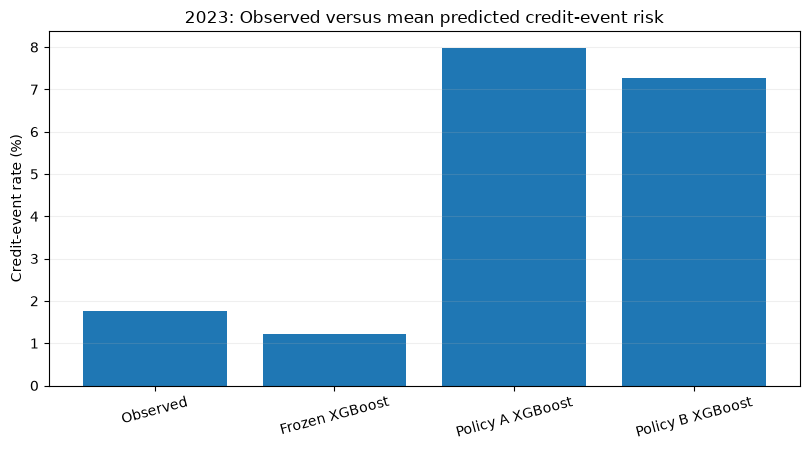

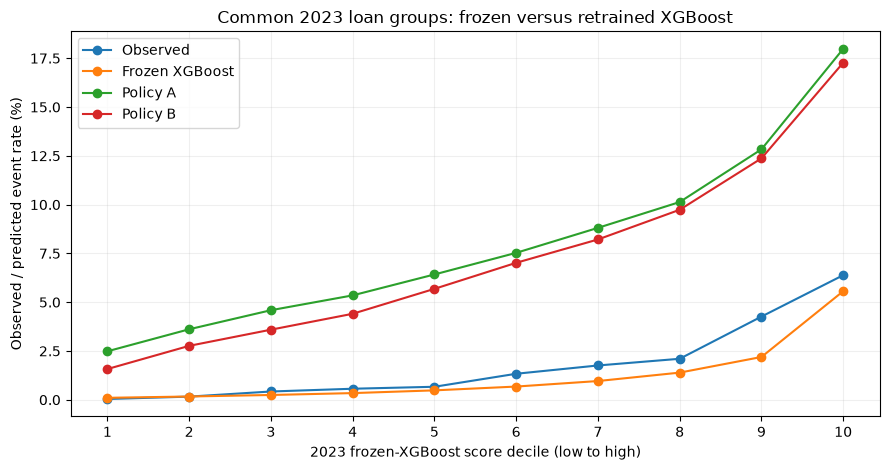

In [6]:
fig_rates, ax=plt.subplots(figsize=(8.2,4.6))
labels=['Observed','Frozen XGBoost','Policy A XGBoost','Policy B XGBoost']
values=[prevalence]
for name in ['frozen','policy_a','policy_b']:
    values.append(float(three.loc[(three.period.eq('2023-all'))&(three.model.eq(name)),
                                  'mean_predicted_risk'].iloc[0]))
ax.bar(labels,[v*100 for v in values])
ax.set_title('2023: Observed versus mean predicted credit-event risk')
ax.set_ylabel('Credit-event rate (%)')
ax.tick_params(axis='x',rotation=15)
ax.grid(axis='y',alpha=.2)
fig_rates.tight_layout()
plt.show()

fig_groups, ax=plt.subplots(figsize=(9,4.8))
for col,label in [('observed_rate','Observed'),('frozen_mean','Frozen XGBoost'),
                  ('policy_a_mean','Policy A'),('policy_b_mean','Policy B')]:
    ax.plot(common_deciles.frozen_score_decile, common_deciles[col]*100,
            marker='o',label=label)
ax.set_xlabel('2023 frozen-XGBoost score decile (low to high)')
ax.set_ylabel('Observed / predicted event rate (%)')
ax.set_title('Common 2023 loan groups: frozen versus retrained XGBoost')
ax.set_xticks(range(1,11))
ax.grid(alpha=.2)
ax.legend()
fig_groups.tight_layout()
plt.show()

## 7. Final interpretation and research limitations

The primary experimental answer concerns **XGBoost retraining**. Logistic Regression remains the frozen benchmark from the original model-development and reliability studies.

The experiment tests **two specific training policies**, not all possible retraining strategies. It does not test new hyperparameters, recalibration, class weighting, changing target definitions or revised features. It also does not establish why overprediction occurs.

In reporting the evidence:

- Differentiate a **numerical change** from a **paired interval that excludes zero**.
- Do not describe historically reconstructed January 2023 availability as verified publication timing.
- Do not describe 2023 as an untouched prospective evaluation set.
- Do not convert this evidence into a universal claim that retraining is ineffective.
- Do not treat PSI or other drift measures as automatic operational retraining triggers.
- Fannie Mae external validation remains a separate planned study.

In [7]:
def pretty(name):
    return {'frozen':'Frozen XGBoost','policy_a':'Policy A XGBoost',
            'policy_b':'Policy B XGBoost'}[name]

ranked = three.loc[three.period.eq('2023-all')].set_index('model')
for model in ['frozen','policy_a','policy_b']:
    row=ranked.loc[model]
    print(f"{pretty(model)}: ROC-AUC={row.roc_auc:.4f}, AP={row.average_precision:.4f}, "
          f"Brier={row.brier:.5f}, mean risk={row.mean_predicted_risk:.2%}, "
          f"absolute risk gap={row.absolute_risk_gap:.2%}")

full_summary=[]
for policy in ['policy_a','policy_b']:
    diff=full_intervals.loc[full_intervals.comparison.eq(policy+'_minus_frozen')]
    supported=[row.metric for row in diff.itertuples()
               if row.ci_high < 0]
    uncertain=[row.metric for row in diff.itertuples()
               if row.ci_low <= 0 <= row.ci_high]
    full_summary.append({'comparison':pretty(policy)+' vs Frozen XGBoost',
                         'metrics_favoring_frozen':', '.join(supported),
                         'metrics_with_uncertain_direction':', '.join(uncertain),
                         'updated_mean_predicted_risk':float(ranked.loc[policy,'mean_predicted_risk']),
                         'observed_rate':prevalence})
conclusion_table=pd.DataFrame(full_summary)
display(conclusion_table)
print('Conclusion: Neither evaluated XGBoost retraining policy improved the overall 2023 reliability profile.')
print('This is a retrospective, policy-specific result; the reasons for overprediction are not established.')

Frozen XGBoost: ROC-AUC=0.7866, AP=0.0593, Brier=0.01710, mean risk=1.21%, absolute risk gap=0.56%
Policy A XGBoost: ROC-AUC=0.7610, AP=0.0535, Brier=0.02267, mean risk=7.97%, absolute risk gap=6.20%
Policy B XGBoost: ROC-AUC=0.7765, AP=0.0561, Brier=0.02207, mean risk=7.26%, absolute risk gap=5.49%


,comparison,metrics_favoring_frozen,metrics_with_uncertain_direction,updated_mean_predicted_risk,observed_rate
0,Policy A XGBoost vs Frozen XGBoost,"roc_auc, average_precision, brier, absolute_ri...",,0.07974,0.017697
1,Policy B XGBoost vs Frozen XGBoost,"roc_auc, brier, absolute_risk_gap",average_precision,0.07263,0.017697


Conclusion: Neither evaluated XGBoost retraining policy improved the overall 2023 reliability profile.
This is a retrospective, policy-specific result; the reasons for overprediction are not established.


## 8. Save a concise final review bundle

Export source-reconciled aggregate results, concise findings, figures and provenance. No raw loan records, individual predictions or serialized models are included in the ZIP. Save the executed notebook separately in VS Code; share the ZIP for review before pushing Notebook 13E to GitHub.

If a complete export already exists, this cell checks the files and calculations again rather than overwriting them. An incomplete or inconsistent folder stops with an explanation.


In [8]:
review_tables={
    'frozen_benchmark_2023.csv':benchmark,
    'frozen_benchmark_all_half_years.csv':half,
    'three_xgboost_model_metrics.csv':three,
    'three_xgboost_paired_intervals.csv':paired,
    'policy_a_training_cohorts.csv':cohort_a,
    'notebook_13c_score_shift.csv':shift,
    'notebook_13c_score_distributions.csv':score_2023,
    'notebook_13c_brier_by_outcome.csv':brier_2023,
    'common_frozen_score_deciles.csv':common_deciles,
    'final_retraining_conclusion_table.csv':conclusion_table,
}

if OUTPUT_DIR.exists():
    # A previous successful export should be reusable, not overwritten. Verify that
    # it matches the source tables recomputed in this run and the saved fingerprints.
    expected_names = [*review_tables,
                      'observed_vs_predicted_2023.png',
                      'three_model_common_deciles.png',
                      'final_retraining_findings.md',
                      'synthesis_manifest.json']
    review_zip = OUTPUT_DIR / 'notebook_13e_synthesis_review.zip'
    require(review_zip.is_file(),
            f'The existing synthesis folder has no review ZIP: {OUTPUT_DIR}. Do not overwrite it.')
    with zipfile.ZipFile(review_zip) as archive:
        require(archive.testzip() is None and set(archive.namelist()) == set(expected_names),
                'Existing review ZIP is incomplete or corrupt. Do not overwrite it.')
        for filename in expected_names:
            file_path = OUTPUT_DIR / filename
            require(file_path.is_file(), f'Existing synthesis file missing: {file_path}')
            require(archive.read(filename) == file_path.read_bytes(),
                    f'ZIP content does not match saved file: {filename}')

    for filename, current in review_tables.items():
        saved = pd.read_csv(OUTPUT_DIR / filename)
        require(list(saved.columns) == list(current.columns) and len(saved) == len(current),
                f'Existing summary table shape differs: {filename}')
        for col in current.columns:
            if pd.api.types.is_numeric_dtype(current[col]):
                np.testing.assert_allclose(
                    saved[col].to_numpy(dtype=float),
                    current[col].to_numpy(dtype=float),
                    rtol=1e-8, atol=1e-10, equal_nan=True,
                    err_msg=f'Existing table differs: {filename}, {col}')
            else:
                require(saved[col].fillna('').astype(str).tolist()
                        == current[col].fillna('').astype(str).tolist(),
                        f'Existing table differs: {filename}, {col}')

    existing = read_json(OUTPUT_DIR / 'synthesis_manifest.json')
    require(existing['evaluation_loans'] == 49501
            and existing['evaluation_events'] == 876
            and existing['policy_b_run_id'] == RUN_ID_B
            and existing['training_or_model_updates_performed'] is False,
            'Existing synthesis manifest uses a different study definition.')
    for key, path in [
        ('frozen_xgboost_sha256', frozen_path),
        ('frozen_logistic_sha256', logistic_path),
        ('policy_a_xgboost_sha256', a_path),
        ('policy_b_xgboost_sha256', b_path),
        ('feature_contract_sha256', FEATURE_CONTRACT),
    ]:
        require(existing[key] == sha256(path), f'Existing synthesis has a different fingerprint: {key}')
    require(existing['model_data_sha256'] == base['input_file_sha256'],
            'Existing synthesis has a different modeling data fingerprint.')
    print('Notebook 13E completed: the previous export was verified against the current calculations.')
    print('No files were overwritten:', OUTPUT_DIR)
    print('Review ZIP:', review_zip)
else:
    OUTPUT_DIR.mkdir(parents=True)
    for name,table in review_tables.items():
        table.to_csv(OUTPUT_DIR/name,index=False)
    fig_rates.savefig(OUTPUT_DIR/'observed_vs_predicted_2023.png',dpi=160,bbox_inches='tight')
    fig_groups.savefig(OUTPUT_DIR/'three_model_common_deciles.png',dpi=160,bbox_inches='tight')

    notes=[
        '# Notebook 13E — Final retraining findings',
        '',
        '### Design',
        'Frozen Logistic Regression is a benchmark from Notebook 11 and was not retrained.',
        'Frozen XGBoost is the primary model. Policy A and Policy B are two XGBoost retraining policies.',
        'The two retrained XGBoost models use the original 29 predictors and frozen preprocessing.',
        'Policy A: 191,015 loans / 2,185 events; Policy B: 285,070 loans / 5,179 events.',
        'All three XGBoost models were evaluated on the same 49,501 loans / 876 events in 2023.',
        '',
        '### 2023 results',
        f'Observed event rate: {prevalence:.4%}.',
    ]
    for model in ['frozen','policy_a','policy_b']:
        r=ranked.loc[model]
        notes.append(f'- {pretty(model)}: ROC-AUC {r.roc_auc:.4f}; AP {r.average_precision:.4f}; '
                     f'Brier {r.brier:.5f}; mean predicted risk {r.mean_predicted_risk:.4%}; '
                     f'absolute risk gap {r.absolute_risk_gap:.4%}.')
    notes.extend(['', '### Paired uncertainty (combined 2023; 1,000 loan-level draws)'])
    for name in ['policy_a_minus_frozen','policy_b_minus_frozen','policy_a_minus_policy_b']:
        notes.append('')
        notes.append(name.replace('_',' ').title()+':')
        for row in full_intervals.loc[full_intervals.comparison.eq(name)].itertuples():
            notes.append(f'- {row.metric}: improvement {row.improvement:.6f}, '
                         f'95% percentile interval [{row.ci_low:.6f}, {row.ci_high:.6f}], '
                         f'{row.direction}.')
    notes.extend(['', '### Interpretation',
        'On the reviewed 2023 evaluation loans, the frozen XGBoost had better observed discrimination and probability reliability than either retrained XGBoost.',
        'Policy B and Policy A showed a broad upward shift in mean predicted risk relative to observed event prevalence.',
        'Notebook 13C identified widespread Policy B overprediction and higher non-event Brier error, but did not establish a causal mechanism.',
        'These results do not imply that all forms of retraining are ineffective.',
        '', '### Limitations',
        '- Historical target availability and publication timing relied on proxies, not verified release dates.',
        '- 2023 outcomes had previously been reviewed; this was not untouched prospective validation.',
        '- Paired bootstrap intervals omit model-training uncertainty and correlated macroeconomic shocks.',
        '- This comparison held features and XGBoost parameters fixed and did not test recalibration.',
        '- Logistic Regression was evaluated only as a frozen benchmark, not as a retrained model.',
        '- Fannie Mae external validation remains separate.',
    ])
    (OUTPUT_DIR/'final_retraining_findings.md').write_text('\n'.join(notes)+'\n',encoding='utf-8')

    manifest={
        'stage':'Notebook 13E final retraining synthesis',
        'analysis_type':'retrospective_exploratory_aggregate_synthesis',
        'decision_month':'2023-01',
        'policy_b_run_id':RUN_ID_B,
        'policy_a_result_dir':str(A_DIR.relative_to(ROOT)),
        'evaluation_loans':49501,
        'evaluation_events':876,
        'predictors':29,
        'logistic_benchmark_retrained':False,
        'xgboost_models_compared':['frozen','policy_a','policy_b'],
        'training_or_model_updates_performed':False,
        'frozen_xgboost_sha256':sha256(frozen_path),
        'frozen_logistic_sha256':sha256(logistic_path),
        'policy_a_xgboost_sha256':sha256(a_path),
        'policy_b_xgboost_sha256':sha256(b_path),
        'feature_contract_sha256':sha256(FEATURE_CONTRACT),
        'model_data_sha256':base['input_file_sha256'],
        'historical_publication_dates_verified':False,
        'untouched_prospective_validation':False,
        'source_notebooks':['11','13','13B','13C','13D'],
        'limitations':[
            'Eligibility and historical readiness were reconstructed retrospectively using timing proxies.',
            '2023 outcomes had been examined before retraining comparisons.',
            'Paired bootstrap omits model training and shared macroeconomic uncertainty.',
            'The Logistic Regression benchmark was not retrained.',
            'No economic cost, trigger threshold, recalibration or external validation concluded here.'
        ]
    }
    (OUTPUT_DIR/'synthesis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')

    names=[*review_tables,'observed_vs_predicted_2023.png','three_model_common_deciles.png',
           'final_retraining_findings.md','synthesis_manifest.json']
    review_zip=OUTPUT_DIR/'notebook_13e_synthesis_review.zip'
    with zipfile.ZipFile(review_zip,'w',compression=zipfile.ZIP_DEFLATED) as archive:
        for name in names:
            archive.write(OUTPUT_DIR/name,arcname=name)
    with zipfile.ZipFile(review_zip) as archive:
        require(archive.testzip() is None and set(archive.namelist())==set(names),
                'Review ZIP failed completeness/integrity check.')
    print('Final synthesis exported:', OUTPUT_DIR)
    print('Upload this aggregate review bundle:', review_zip)
    print('All previous models, training data and source notebooks remain unchanged.')


Notebook 13E completed: the previous export was verified against the current calculations.
No files were overwritten: E:\capstone_project\mortgage-model-reliability\data\processed\Freddie_Mac\notebook_13_final_retraining_synthesis\20261111T161902005765Z
Review ZIP: E:\capstone_project\mortgage-model-reliability\data\processed\Freddie_Mac\notebook_13_final_retraining_synthesis\20261111T161902005765Z\notebook_13e_synthesis_review.zip


## Review gate and next milestone

**Before pushing Notebook 13E to GitHub:** Upload `notebook_13e_synthesis_review.zip` and review the saved outputs. Once they are validated, save the executed notebook (`Ctrl + S`) and push only this notebook to `feature/freddie-retraining-feasibility`.

After the retraining synthesis is closed, continue to the **planned Fannie Mae external-validation analysis** and then the final capstone integration of drift, reliability, candidate early signals, retraining and external evidence.